# NumCompute streaming quickstart

Read one CSV, learn from its chunks, then use a decision tree to predict cities. We first explore each module, then put the steps together with Pipeline and StreamTrainer. Plots and performance tables come last.

## 0. Set up and run

From the project root, install the package with `python -m pip install -e ".[test]"` and notebook tools with `python -m pip install ipython ipykernel`. Open this notebook, choose that Python environment, restart the kernel and click **Run All**. Start from the project root or the `demo/` folder.

Our CSV has 3,000 fictional records. **Age and income are the inputs; city is the target.** Missing cells and unusual incomes are intentional. We use real tree predictions, not the older `city_predict` column. Section 9 uses separate fixed-seed benchmark data.

In [1]:
import sys
from pathlib import Path
import numpy as np

# Find the project from either the root or the demo folder.
root = Path.cwd() if (Path.cwd() / "numcompute").is_dir() else Path.cwd().parent
sys.path.insert(0, str(root))
sample_path = root / "demo" / "data" / "sample.csv"

from numcompute import io
from numcompute_stream import preprocessing as pp, stats, metrics, visualise, benchmarking
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.stream import StreamTrainer

np.set_printoptions(precision=3, suppress=True)

## 1. Read the CSV in chunks (`io.py`)

`iter_csv_chunks` returns arrays of up to 200 rows. Missing tokens such as blank cells, NA, NULL and N/A become empty text. We convert the two numeric columns to floats, using NaN for missing numbers, and keep city as text.

We read the file **once** and save the chunks for the later examples. This makes a small demo easy to replay. For a large stream, we would process each chunk as it arrives instead of keeping the whole file.

In [2]:
chunk_size = 200
chunks = []

for raw in io.iter_csv_chunks(
    sample_path, chunk_size=chunk_size, usecols=["age", "income", "city"],
):
    # Empty numeric cells become NaN; city labels stay as text.
    X = np.where(raw[:, :2] == "", "nan", raw[:, :2]).astype(float)
    chunks.append((X, raw[:, 2].copy()))

# Reuse these arrays throughout the notebook.
X_chunks = [X for X, _ in chunks]
city_chunks = [city[:, None] for _, city in chunks]  # Keep a 2-D text column.
X_all = np.vstack(X_chunks)
city_all = np.vstack(city_chunks)
first_chunk = X_chunks[0]

print("Rows / chunks / numeric features:", len(X_all), len(chunks), X_all.shape[1])
print("Missing age / income:", np.isnan(X_all).sum(axis=0))
print("Blank city labels:", (city_all == "").sum())
print("First five rows [age, income, city]:\n", np.column_stack((X_all[:5], city_all[:5])))

Rows / chunks / numeric features: 3000 15 2
Missing age / income: [180 240]
Blank city labels: 80
First five rows [age, income, city]:
 [['56.0' '81699.13' 'Hobart']
 ['50.0' '48741.14' 'Hobart']
 ['56.0' '54486.45' 'Hobart']
 ['35.0' '84968.44' 'Melbourne']
 ['70.0' '74190.3' 'Hobart']]


### 1.1 Keep some chunks for testing

A blank city gives us no correct answer, so we exclude that row from training and evaluation. Missing age or income is kept: preprocessing or the tree can handle it.

The first 12 chunks train the models in Sections 4–6. The last 3 chunks are held out for evaluation. Sections 2–3 only explore the data with separate objects; their learned values are not passed into these models.

In [3]:
# Keep the arrival order, but remove rows without a target.
stream_chunks = [(X[city != ""], city[city != ""]) for X, city in chunks]
split = int(0.8 * len(stream_chunks))
train_chunks = stream_chunks[:split]
test_chunks = stream_chunks[split:]

# Join the same cached rows when an example needs a full array.
X_train = np.vstack([X for X, _ in train_chunks])
y_train = np.concatenate([y for _, y in train_chunks])
X_test = np.vstack([X for X, _ in test_chunks])
y_test = np.concatenate([y for _, y in test_chunks])

print("Training rows:", len(y_train))
print("Held-out test rows:", len(y_test))
print("Cities:", np.unique(y_train))

Training rows: 2334
Held-out test rows: 586
Cities: ['Adelaide' 'Brisbane' 'Hobart' 'Melbourne' 'Perth' 'Sydney']


## 2. Learn preprocessing values (`preprocessing.py`)

`fit` starts a new fit. `partial_fit` adds a chunk to what has already been learned. Both return the object itself. `transform` returns the processed data without learning again.

### 2.1 Update scalers

StandardScaler keeps a running mean and variance. Each update includes earlier chunks, not just the newest one. MinMaxScaler keeps the smallest and largest values seen so far. Both learn from nonmissing values in each column.

In [4]:
scaler = pp.StandardScaler()
minmax = pp.MinMaxScaler(feature_range=(0, 1))

for number, X in enumerate(X_chunks, start=1):
    scaler.partial_fit(X)
    minmax.partial_fit(X)

    if number <= 2:
        print(f"After chunk {number}: mean={scaler.mean_}, variance={scaler.var_}")

# Apply the final learned values to the same saved rows.
Z = scaler.transform(X_all)
scaled_01 = minmax.transform(X_all)

print("Final valid counts [age, income]:", scaler.n_samples_seen_)
print("Standardized means / stds:", np.nanmean(Z, axis=0), np.nanstd(Z, axis=0))
print("MinMax minimum / maximum:", np.nanmin(scaled_01, axis=0), np.nanmax(scaled_01, axis=0))
print("Missing cells are still present:", np.isnan(Z).sum())

After chunk 1: mean=[   42.135 83924.003], variance=[1.112e+02 5.064e+08]
After chunk 2: mean=[   42.406 85897.876], variance=[1.238e+02 1.136e+09]
Final valid counts [age, income]: [2820 2760]
Standardized means / stds: [-0. -0.] [1. 1.]
MinMax minimum / maximum: [0. 0.] [1. 1.]
Missing cells are still present: 420


The standardized columns have mean near 0 and standard deviation near 1; a printed `-0.` is just rounding. MinMax maps the observed column range to 0–1. Scaling does not fill NaN. These final summaries describe all chunks added so far.

### 2.2 Fill missing numbers

The imputer updates its fill values as chunks arrive. Mean filling uses running sums/counts. Exact median filling keeps the observed history; averaging chunk medians would not give the overall median. Neither learns from its own filled values.

In [5]:
mean_imputer = pp.SimpleImputer(strategy="mean")
median_imputer = pp.SimpleImputer(strategy="median")

for number, X in enumerate(X_chunks, start=1):
    mean_imputer.partial_fit(X)
    median_imputer.partial_fit(X)

    if number <= 2:
        print(f"After chunk {number}: mean fill={mean_imputer.statistics_}")

# Transform uses the latest fill values, without another update.
X_filled = median_imputer.transform(X_all)
print("Final mean fill [age, income]:", mean_imputer.statistics_)
print("Final median fill [age, income]:", median_imputer.statistics_)
print("Missing cells before / after:", np.isnan(X_all).sum(), np.isnan(X_filled).sum())

After chunk 1: mean fill=[   42.135 83924.003]
After chunk 2: mean fill=[   42.406 85897.876]
Final mean fill [age, income]: [   42.327 87823.689]
Final median fill [age, income]: [   42.    82603.155]
Missing cells before / after: 420 0


### 2.3 Learn new city categories

Here city is an example of a categorical **input**, not a feature used to predict itself. A constant imputer can replace a blank with `Unknown`.

We hold Sydney back to show a new category arriving. With `handle_unknown="ignore"`, it initially gets all zeros. After `partial_fit` learns Sydney, it gets its own column. Categories stay sorted, so adding one can change both the width and column positions. Re-encode old raw rows before combining outputs from different stages.

In [6]:
city_imputer = pp.SimpleImputer(fill_value="Unknown")
encoder = pp.OneHotEncoder(handle_unknown="ignore")

for city in city_chunks:
    city_imputer.partial_fit(city)
    encoder.partial_fit(city[city[:, 0] != "Sydney"])

blank_city = city_all[city_all[:, 0] == ""][:1]
sydney = city_all[city_all[:, 0] == "Sydney"][:1]
print("Blank after filling:", city_imputer.transform(blank_city).ravel())
print("Categories before Sydney:", encoder.categories_[0])
print("Sydney before learning:", encoder.transform(sydney))

# The next update adds a category to the existing encoder.
encoder.partial_fit(sydney)
print("Categories after Sydney:", encoder.categories_[0])
print("Sydney / blank encodings:\n", encoder.transform(np.vstack((sydney, blank_city))))

Blank after filling: ['Unknown']
Categories before Sydney: ['Adelaide' 'Brisbane' 'Hobart' 'Melbourne' 'Perth']
Sydney before learning: [[0. 0. 0. 0. 0.]]
Categories after Sydney: ['Adelaide' 'Brisbane' 'Hobart' 'Melbourne' 'Perth' 'Sydney']
Sydney / blank encodings:
 [[0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0.]]


## 3. Summarize the stream (`stats.py`)

### 3.1 Running mean, variance and range

`update` adds a chunk to the same RunningStats object. `n` counts received rows; `count_` counts nonmissing values per feature. We get one result per column: age, then income. These are summaries of the data, not model training.

Variance and standard deviation use `ddof=0` by default. Use `ddof=1` for sample estimates.

In [7]:
running = stats.RunningStats()

for number, X in enumerate(X_chunks, start=1):
    running.update(X)

    if number <= 2:
        print(f"After chunk {number}: rows={running.n}, mean={running.mean}")

print("Final rows / valid counts:", running.n, running.count_)
print("Mean:", running.mean)
print("Variance:", running.var())
print("Std:", running.std())
print("Min / max:", running.min, running.max)

After chunk 1: rows=200, mean=[   42.135 83924.003]
After chunk 2: rows=400, mean=[   42.406 85897.876]
Final rows / valid counts: 3000 [2820 2760]
Mean: [   42.327 87823.689]
Variance: [1.243e+02 1.771e+09]
Std: [   11.149 42079.088]
Min / max: [   18.   33020.42] [    70. 690000.]


### 3.2 Quantiles and an income histogram

Quartiles mark the 25%, 50% and 75% positions. Here each row of the quantile result is a quartile, and each column is a feature. The histogram counts incomes in six ranges; the high-income ranges show the long tail.

Exact quantiles, medians and histograms use saved history. For moments such as mean and variance, `store_data=False` avoids keeping old rows. `update_stats(chunk, accumulator)` updates the supplied object; `partial_fit` is another name for `update`. `reset` clears the learned state.

In [8]:
print("Quartiles [age, income]:\n", running.quantile([0.25, 0.5, 0.75]))
print("Median [age, income]:", running.median())

counts, edges = running.histogram(bins=6, feature=1)  # Income is column 1.
print("Income bin edges:", edges)
print("Counts:", counts, "| observed incomes:", counts.sum())

# Keep only running moments when exact distribution queries are not needed.
moments = stats.RunningStats(store_data=False)
for X in X_chunks:
    stats.update_stats(X, moments)
print("Mean without saved history:", moments.mean)

moments.reset()
moments.partial_fit(first_chunk)
print("Rows after reset and one new chunk:", moments.n)

Quartiles [age, income]:
 [[    34.     66329.5  ]
 [    42.     82603.155]
 [    50.    104537.24 ]]
Median [age, income]: [   42.    82603.155]
Income bin edges: [ 33020.42  142517.017 252013.613 361510.21  471006.807 580503.403
 690000.   ]
Counts: [2740    2    3    6    3    6] | observed incomes: 2760
Mean without saved history: [   42.327 87823.689]
Rows after reset and one new chunk: 200


## 4. Train a decision tree (`tree.py`)

### 4.1 Fit once on the training set

The tree learns questions such as “is income below this value?” Gini or entropy measures how mixed the classes are. `max_depth` limits depth, `min_samples_split` limits when a split is attempted, and `max_features` can limit the features checked. The tree also learns where to send NaN feature values.

`fit(X, y)` uses **all supplied training rows**. The buffer size does not limit this method. We predict the held-out rows without fitting on them.

In [9]:
fit_tree = DecisionTreeClassifier(
    max_depth=5, min_samples_split=2, criterion="gini", buffer_size=500,
)
fit_tree.fit(X_train, y_train)
fit_predictions = fit_tree.predict(X_test)

print("Rows used by fit:", fit_tree.n_training_samples_)
print("First predictions [true, predicted]:\n", np.column_stack((y_test[:5], fit_predictions[:5])))

Rows used by fit: 2334
First predictions [true, predicted]:
 [['Hobart' 'Brisbane']
 ['Brisbane' 'Brisbane']
 ['Sydney' 'Sydney']
 ['Sydney' 'Melbourne']
 ['Brisbane' 'Brisbane']]


### 4.2 Learn from a buffer with partial_fit

Each call adds rows to a buffer. At **at least 500 rows**, the tree trains on the whole buffer, replaces the earlier tree, and clears the buffer. It cannot predict before the first retrain; between retrains it uses the latest trained tree.

500 is a threshold, not a strict training-set size. The latest tree only uses its most recent full buffer. Earlier rows trained earlier trees; they are not all kept in the final one. Any incomplete final buffer stays pending. Section 7 uses those earlier trees to make predictions while the stream arrives.

In [10]:
tree = DecisionTreeClassifier(max_depth=5, buffer_size=500)

print("Training chunk | rows waiting | retrains")
for number, (X, y) in enumerate(train_chunks, start=1):
    tree.partial_fit(X, y)
    print(f"{number:14d} | {tree.n_buffered_samples_:12d} | {tree.n_retrains_:8d}")

# Predict each held-out chunk once, then reuse these real predictions below.
test_predictions = [(y, tree.predict(X)) for X, y in test_chunks]
y_true = np.concatenate([truth for truth, _ in test_predictions])
y_pred = np.concatenate([prediction for _, prediction in test_predictions])

print("Rows used by the latest tree:", tree.n_training_samples_)
print("First test rows [true, predicted]:\n", np.column_stack((y_true[:8], y_pred[:8])))

Training chunk | rows waiting | retrains
             1 |          192 |        0
             2 |          390 |        0
             3 |            0 |        1
             4 |          195 |        1
             5 |          389 |        1
             6 |            0 |        2
             7 |          198 |        2
             8 |          394 |        2
             9 |            0 |        3
            10 |          198 |        3
            11 |          394 |        3
            12 |            0 |        4
Rows used by the latest tree: 587
First test rows [true, predicted]:
 [['Hobart' 'Brisbane']
 ['Brisbane' 'Brisbane']
 ['Sydney' 'Sydney']
 ['Sydney' 'Melbourne']
 ['Brisbane' 'Hobart']
 ['Melbourne' 'Melbourne']
 ['Perth' 'Perth']
 ['Melbourne' 'Melbourne']]


## 5. Read the prediction scores (`metrics.py`)

### 5.1 Update classification metrics

`update` adds another set of answers; `result` reads the score. Accuracy is the share correct. Precision asks how often a predicted city is right; recall asks how many people from that city we found. F1 balances both. Macro averaging gives each city equal weight.

We reuse the buffered tree's held-out predictions, one chunk at a time. Cumulative accuracy weights rows equally, even when chunks have different sizes.

In [11]:
scores = {
    "accuracy": metrics.Accuracy(),
    "precision": metrics.Precision(average="macro"),
    "recall": metrics.Recall(average="macro"),
    "f1": metrics.F1(average="macro"),
}
confusion = metrics.ConfusionMatrix()
recent = metrics.Accuracy(window_size=500)

for number, (truth, prediction) in enumerate(test_predictions, start=1):
    for metric in scores.values():
        metric.update(truth, prediction)
    confusion.update(truth, prediction)
    recent.update(truth, prediction)

    print(f"After test chunk {number}: accuracy={scores['accuracy'].result():.3f}")

print("\nFinal held-out scores:")
for name, metric in scores.items():
    print(f"{name:9s}: {metric.result():.3f}")

After test chunk 1: accuracy=0.751
After test chunk 2: accuracy=0.743
After test chunk 3: accuracy=0.741

Final held-out scores:
accuracy : 0.741
precision: 0.744
recall   : 0.739
f1       : 0.737


### 5.2 Confusion matrix, rolling window and reset

Matrix rows are true cities; columns are predicted cities. The diagonal counts correct answers. `labels_` gives the city order.

The rolling metric only keeps the latest **500 samples**, not 500 chunks. It can differ from the cumulative score when performance changes. `reset` starts a fresh evaluation without retraining the model.

In [12]:
print("City order:", confusion.labels_)
print("Confusion matrix:\n", confusion.result())
print("Latest 500-row accuracy:", round(recent.result(), 3))

# Clear this metric, then start a new evaluation on one saved test chunk.
recent.reset()
print("Rows counted after reset:", recent.n_samples_seen_)

truth, prediction = test_predictions[0]
recent.update(truth, prediction)
print("New evaluation on the first test chunk:", round(recent.result(), 3))

City order: ['Adelaide' 'Brisbane' 'Hobart' 'Melbourne' 'Perth' 'Sydney']
Confusion matrix:
 [[72  9  0 16  0  0]
 [15 49 11 12  3  0]
 [ 3 11 81  2  1  0]
 [ 1  1  0 71  8 10]
 [ 0  2  6 12 73 15]
 [ 0  1  1  8  4 88]]
Latest 500-row accuracy: 0.738
Rows counted after reset: 0
New evaluation on the first test chunk: 0.751


### 5.3 Sydney or not: ROC, AUC and MSE

Turn true cities and predicted cities into 1 for Sydney and 0 for the rest. The tree returns labels, not probabilities, so this ROC has only a few points. AUC summarizes this coarse ranking; exact AUC is calculated from all accumulated answers, not by averaging chunk AUCs.

MSE normally measures numeric prediction error. With these 0/1 answers, it equals the fraction wrong on the Sydney question. We do not assign numeric distances to city names.

In [13]:
roc = metrics.ROCCurve()
area = metrics.AUC()
binary_error = metrics.MSE()

for truth, prediction in test_predictions:
    target = (truth == "Sydney").astype(int)
    score = (prediction == "Sydney").astype(float)
    roc.update(target, score)
    area.update(target, score)
    binary_error.update(target, score)

fpr, tpr, thresholds = roc.result()
print("Threshold | false-positive rate | true-positive rate")
print(np.column_stack((thresholds, fpr, tpr)))
print("Sydney AUC:", round(area.result(), 3))
print("Sydney indicator MSE:", round(binary_error.result(), 3))

Threshold | false-positive rate | true-positive rate
[[  inf 0.    0.   ]
 [1.    0.052 0.863]
 [0.    1.    1.   ]]
Sydney AUC: 0.906
Sydney indicator MSE: 0.067


## 6. Put the steps in a Pipeline (`pipeline.py`)

### 6.1 Chain preprocessing

A pipeline sends each step's output into the next step. Here `fit_transform` learns median filling and scaling from the training rows. `transform` applies those same values to held-out rows. Test means do not have to be zero: test data is not fitted again.

For incremental use, `partial_fit` updates each transformer in order before passing its transformed chunk to the next step.

In [14]:
numeric_pipe = Pipeline([
    ("impute", pp.SimpleImputer(strategy="median")),
    ("scale", pp.StandardScaler()),
])

X_train_ready = numeric_pipe.fit_transform(X_train)
X_test_ready = numeric_pipe.transform(X_test)

print("Training / test shapes:", X_train_ready.shape, X_test_ready.shape)
print("Training means:", X_train_ready.mean(axis=0))
print("Test means:", X_test_ready.mean(axis=0))
print("First processed test rows:\n", X_test_ready[:3])

Training / test shapes: (2334, 2) (586, 2)
Training means: [ 0. -0.]
Test means: [0.105 0.039]
First processed test rows:
 [[ 0.455 -0.126]
 [ 0.361 -0.317]
 [ 0.08   0.747]]


### 6.2 Fill and encode text

The same chaining works for text inputs. We update the pipeline with each saved city chunk. Missing city inputs now become `Unknown` and activate that column, rather than getting all zeros. This is a preprocessing example; blank target labels are still excluded from model training.

In [15]:
category_pipe = Pipeline([
    ("impute", pp.SimpleImputer(fill_value="Unknown")),
    ("encode", pp.OneHotEncoder()),
])

for city in city_chunks:
    category_pipe.partial_fit(city)

print("Final category order:", category_pipe.steps[-1][1].categories_[0])
print("Output shape:", category_pipe.transform(city_all).shape)
print("Originally blank city:\n", category_pipe.transform(blank_city))

Final category order: ['Adelaide' 'Brisbane' 'Hobart' 'Melbourne' 'Perth' 'Sydney' 'Unknown']
Output shape: (3000, 7)
Originally blank city:
 [[0. 0. 0. 0. 0. 0. 1.]]


### 6.3 Put the tree at the end

A transformer supplies `fit`, `partial_fit` and `transform`. A model supplies `fit`, `partial_fit` and `predict`. Pipeline calls those methods; components do not need to inherit from the protocols. Only the final model receives y.

Use **constant filling** before the buffered tree. A changing scaler or mean imputer would change how later chunks are represented, while older transformed rows remain in the buffer. This pipeline does not reprocess those older rows. Constant filling keeps the representation consistent.

In [16]:
pipeline_tree = DecisionTreeClassifier(max_depth=5, buffer_size=500)
model_pipe = Pipeline([
    ("impute", pp.SimpleImputer(fill_value=0)),
    ("model", pipeline_tree),
])

for X, y in train_chunks:
    model_pipe.partial_fit(X, y)

# predict fills test NaNs, then calls the tree; it does not train again.
pipeline_predictions = model_pipe.predict(X_test)
pipeline_score = metrics.Accuracy().update(y_test, pipeline_predictions)

print("Pipeline held-out accuracy:", round(pipeline_score.result(), 3))
print("First predictions:", pipeline_predictions[:8])
print("Tree retrains:", pipeline_tree.n_retrains_)

Pipeline held-out accuracy: 0.73
First predictions: ['Brisbane' 'Brisbane' 'Sydney' 'Melbourne' 'Hobart' 'Melbourne' 'Perth'
 'Melbourne']
Tree retrains: 4


## 7. Run the full stream (`stream.py`)

Start fresh and replay all cached chunks. StreamTrainer combines our pipeline, metrics and logs. `fit_chunk` calls `partial_fit`; `score_chunk` predicts and updates metrics without training.

After warm-up, **test each chunk before learning from it**. This shows how the model handles unseen rows. While the tree waits for enough rows, store NaN in the curve: no score is different from zero accuracy. We save the latest predictions before training for the plot in Section 8.

In [17]:
online_tree = DecisionTreeClassifier(max_depth=5, buffer_size=500)
online_pipe = Pipeline([
    ("impute", pp.SimpleImputer(fill_value=0)),
    ("model", online_tree),
])
trainer = StreamTrainer(online_pipe, metrics={
    "f1": metrics.F1(average="macro"),
    "recent_accuracy": metrics.Accuracy(window_size=500),
})

chunk_curve_500 = np.full(len(stream_chunks), np.nan)
cumulative_curve = np.full(len(stream_chunks), np.nan)

for position, (X, y) in enumerate(stream_chunks):
    if online_tree.n_retrains_:
        # Save predictions before learning the final chunk.
        if position == len(stream_chunks) - 1:
            latest_true = y.copy()
            latest_pred = online_pipe.predict(X)

        row = trainer.score_chunk(X, y)
        chunk_curve_500[position] = row["accuracy"]
        cumulative_curve[position] = row["cumulative_accuracy"]

    trainer.fit_chunk(X, y)  # Always learn after scoring.

print("Training / scoring calls:", trainer.n_fit_chunks_, trainer.n_score_chunks_)
print("Rows submitted / scored:", trainer.n_trained_samples_, trainer.n_scored_samples_)

Training / scoring calls:

 15 12
Rows submitted / scored: 2920 2338


### 7.1 Read the logs

Each successful call logs its event, row counts, runtime, estimated memory, buffer state and scores. Chunk accuracy describes just that chunk. Cumulative accuracy includes every scored row so far; recent accuracy only includes the latest 500.

Memory is a rough size of retained model/metric state, not total process RAM or peak memory. Runtime covers training or prediction/metrics; it leaves out the first input checks and log/memory bookkeeping.

In [18]:
fit_logs = [row for row in trainer.logs_ if row["event"] == "fit"]
score_logs = [row for row in trainer.logs_ if row["event"] == "score"]
last_score = score_logs[-1]
last_fit = fit_logs[-1]

print("Latest chunk accuracy:", round(last_score["accuracy"], 3))
print("Cumulative accuracy:", round(last_score["cumulative_accuracy"], 3))
print("Macro F1:", round(last_score["metrics"]["f1"], 3))
print("Recent accuracy:", round(last_score["metrics"]["recent_accuracy"], 3))
print(f"Last update: {last_fit['seconds'] * 1000:.2f} ms")
print(f"Estimated retained state: {last_fit['memory_bytes'] / 1024:.1f} KiB")
print("Pending rows / retrains:", last_fit["buffered_samples"], last_fit["n_retrains"])

Latest chunk accuracy: 0.71
Cumulative accuracy: 0.701
Macro F1: 0.7
Recent accuracy: 0.728
Last update: 5.40 ms
Estimated retained state: 54.3 KiB
Pending rows / retrains: 0 5


## 8. Show the results (`visualise.py`)

The plotting functions use the results we already collected and return `(fig, ax)`. They can show plots inline or save them with `save_path`.

The first scored point is **chunk 4**: three chunks are needed to fill the first buffer, then we test chunk 4 before training on it. NaN leaves a gap during warm-up. A rising cumulative curve means the overall fraction correct is improving; it need not rise after every chunk.

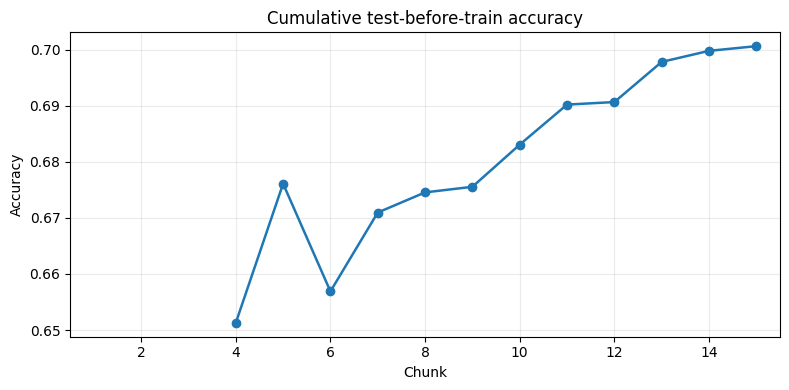

In [19]:
%matplotlib inline

# Draw the scores saved during the stream loop.
fig, ax = visualise.plot_metric_over_time(
    cumulative_curve,
    title="Cumulative test-before-train accuracy",
    ylabel="Accuracy",
)

# To save too, add save_path=root / "demo" / "figures" / "accuracy.png".

### 8.1 Compare buffer sizes

Replay the same stream with a fresh model and `buffer_size=1000`. The only model setting we change is the buffer size. A larger buffer needs longer warm-up and retrains less often.

Both curves use the same chunk positions. Compare the chunks where both have a score. Section 9 uses a shared scoring period for its overall accuracy comparison; a larger buffer does not always improve accuracy.

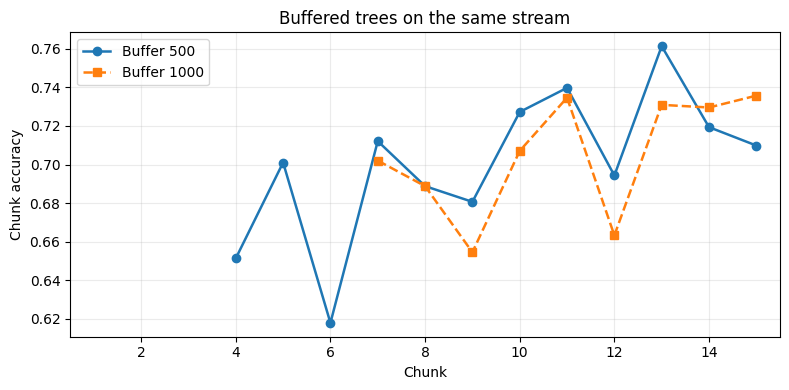

In [20]:
large_tree = DecisionTreeClassifier(max_depth=5, buffer_size=1000)
large_trainer = StreamTrainer(Pipeline([
    ("impute", pp.SimpleImputer(fill_value=0)),
    ("model", large_tree),
]))
chunk_curve_1000 = np.full(len(stream_chunks), np.nan)

for position, (X, y) in enumerate(stream_chunks):
    if large_tree.n_retrains_:
        chunk_curve_1000[position] = large_trainer.score_chunk(X, y)["accuracy"]
    large_trainer.fit_chunk(X, y)

fig, ax = visualise.compare_models(
    chunk_curve_500, chunk_curve_1000,
    labels=("Buffer 500", "Buffer 1000"),
    title="Buffered trees on the same stream",
    ylabel="Chunk accuracy",
)

### 8.2 Look at individual predictions

Show 30 rows from the latest scored chunk, using the predictions saved **before** that chunk was trained. Circles are true cities; crosses are predictions. Overlap means a correct answer. Cities on the vertical axis are categories, not distances.

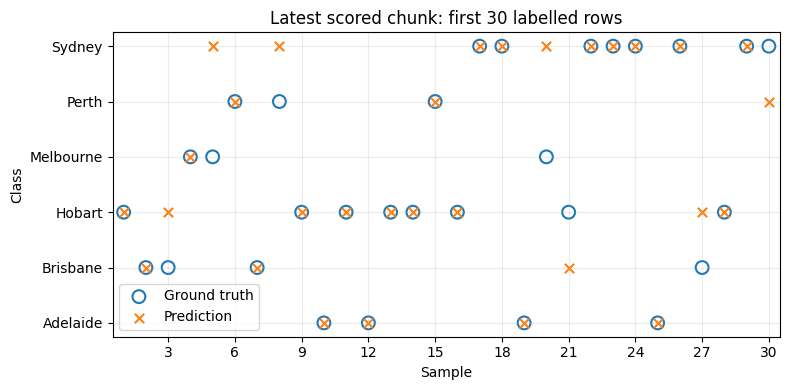

In [21]:
fig, ax = visualise.plot_predictions_vs_ground_truth(
    latest_true[:30], latest_pred[:30],
    title="Latest scored chunk: first 30 labelled rows",
)

## 9. Run benchmarks (`benchmark/` and `benchmarking.py`)

`stream_loops.py` contains Python-loop baselines. `run_stream_benchmarks.py` prepares fixed-seed data, runs comparisons and formats the tables. This section does not read sample.csv. First list the cases and try one small case, then run the full set.

The first table has all **13 comparisons**: running statistics, both scalers, mean/median imputation, one-hot encoding, histogram, quantiles, MSE, AUC, Gini/entropy split search and prediction. The runner checks matching answers before timing. Update cases start fresh; query cases use prepared history.

Speed-up is loop time divided by NumPy time. Above 1 means faster; below 1 means slower. Some changes also use a different algorithm, as the notes explain. Accuracy and ConfusionMatrix are not timed against simple counting loops because those loops do less work than their full APIs.

The second table compares buffers **100, 500, 1000, 2000 and 4000** on the same scoring rows after shared warm-up. Update time excludes prediction; retrain-call time includes checks and joining the buffer. Final pending rows are not forced into a retrain. Timings depend on the computer and background load.

From a terminal, run `python -m benchmark.run_stream_benchmarks`, or add `--quick` for a small run.

In [22]:
from IPython.display import Markdown, display
from benchmark import run_stream_benchmarks as stream_bench

# Show which operations will be compared.
cases = stream_bench.build_cases(stream_bench.QUICK, np.random.default_rng(stream_bench.SEED))
for name, _, _, _ in cases:
    print(name)

# Try one small case before running the full benchmark.
name, loop_func, vec_func, notes = cases[0]
preview = benchmarking.compare(name, loop_func, vec_func, repeat=1, rtol=1e-6)
preview["notes"] = notes
display(Markdown(benchmarking.format_table([preview])))

stats.RunningStats n=1,000, d=3, chunk=200
preprocessing.StandardScaler n=1,000, d=3
preprocessing.MinMaxScaler n=1,000, d=3
preprocessing.SimpleImputer(mean) n=1,000, d=3
preprocessing.SimpleImputer(median) n=600, d=3
preprocessing.OneHotEncoder n=1,000, d=3
stats.histogram n=600, bins=20
stats.quantile(linear) n=600
metrics.MSE n=1,000
metrics.AUC n=100
tree split search(gini) n=60, d=4
tree split search(entropy) n=60, d=4
tree.predict n=1,000


| Operation | NumCompute result | Baseline/result | Notes |
|---|---:|---:|---|
| stats.RunningStats n=1,000, d=3, chunk=200 | 0.366 ms | 0.422 ms (1.2x) | Per-cell Welford vs vectorised chunk merging; NaNs ignored per feature |

In [23]:
# Run all 13 full-size comparisons and all five buffer settings.
# Keep the report in this notebook; do not overwrite the saved benchmark file.
benchmark_report = stream_bench.run(quick=False)
display(Markdown(benchmark_report))

  stats.RunningStats n=50,000, d=6, chunk=500 ...


  preprocessing.StandardScaler n=50,000, d=6 ...


  preprocessing.MinMaxScaler n=50,000, d=6 ...


  preprocessing.SimpleImputer(mean) n=50,000, d=6 ...


  preprocessing.SimpleImputer(median) n=5,000, d=6 ...


  preprocessing.OneHotEncoder n=20,000, d=3 ...


... (4 outputs left out)

  tree split search(gini) n=400, d=4 ...


  tree split search(entropy) n=400, d=4 ...


  tree.predict n=50,000 ...


# Streaming benchmark results

Generated by `python -m benchmark.run_stream_benchmarks`; seed=42, repeats=5, elapsed=5.5 s.

## Environment

- python: 3.12.8
- numpy: 2.2.4
- os: Windows-10-10.0.19045-SP0
- cpu: Intel64 Family 6 Model 151 Stepping 2, GenuineIntel
- cpu_count: 20

## Performance table

All function comparisons are in one table. Answers are checked before timing. Update cases start fresh; histogram/quantile queries reuse saved history, and prediction uses the same fitted tree. Input lists are prepared beforehand, apart from internal node-to-list conversion in the split loop. Normal validation stays included. Times are medians; speed-up = loop/NumPy time, including values below 1.

Accuracy is not included: the current class builds confusion counts, while a simple accuracy loop only counts matches. ConfusionMatrix is also left out of the speed-up examples: dictionary counting and per-chunk label/schema management add different work. Their correctness is still checked by the unit tests and demo.

| Operation | NumCompute result | Baseline/result | Notes |
|---|---:|---:|---|
| stats.RunningStats n=50,000, d=6, chunk=500 | 8.848 ms | 37.678 ms (4.3x) | Per-cell Welford vs vectorised chunk merging; NaNs ignored per feature |
| preprocessing.StandardScaler n=50,000, d=6 | 11.933 ms | 100.152 ms (8.4x) | Fresh partial_fit sequence, then transform using final parameters |
| preprocessing.MinMaxScaler n=50,000, d=6 | 6.782 ms | 106.567 ms (15.7x) | Learn cumulative minima/maxima, then scale; same constant-column and NaN rules |
| preprocessing.SimpleImputer(mean) n=50,000, d=6 | 4.919 ms | 82.124 ms (16.7x) | Observed cells only; missing estimates updated across chunks |
| preprocessing.SimpleImputer(median) n=5,000, d=6 | 3.510 ms | 13.704 ms (3.9x) | Exact medians updated after every chunk on both sides; then fill using final medians |
| preprocessing.OneHotEncoder n=20,000, d=3 | 23.544 ms | 21.890 ms (0.9x) | Learn categories across chunks, then create the same sorted dense encoding; blanks/nan/None are missing |
| stats.histogram n=5,000, bins=20 | 0.053 ms | 0.813 ms (15.3x) | Query already saved chunks with identical fixed edges; NaNs skipped and last edge included |
| stats.quantile(linear) n=5,000 | 0.115 ms | 0.460 ms (4.0x) | Query already saved chunks; same linear quartiles; Python sorts while NumPy may use selection |
| metrics.MSE n=50,000 | 1.314 ms | 4.754 ms (3.6x) | Squared errors accumulated across chunks |
| metrics.AUC n=1,000 | 0.129 ms | 4.361 ms (33.8x) | Different algorithms: compare all positive-negative pairs vs sort scores once; same exact AUC |
| tree split search(gini) n=400, d=4 | 0.697 ms | 76.824 ms (110.3x) | Different algorithms: scan rows for each threshold vs cumulative counts; same depth-one fit and NaN rules; list conversion included |
| tree split search(entropy) n=400, d=4 | 0.709 ms | 76.646 ms (108.0x) | Same entropy criterion and zero-count rules; repeated row scans vs cumulative class counts |
| tree.predict n=50,000 | 2.206 ms | 18.197 ms (8.2x) | Same fitted tree; per-row traversal vs grouped NumPy traversal |

Notes explain algorithm differences too: AUC uses sorting instead of pair checks; split search uses cumulative counts instead of repeated scans; quantiles may use selection instead of sorting. Those speed-ups are not only due to vectorisation. Hardware and background load affect timings.

## Buffer-size comparison

Stream: 6000 rows, 4 features, chunks of 200, max_depth=5, tree seed=42. Independent seed=43 generates this stream.

All configurations score the same chunks after the largest buffer first trains, before training on those rows. Final pending buffers are not flushed. Total update time excludes prediction; mean retrain call includes validation and buffer concatenation. Timings are medians across fresh runs; accuracy need not increase with buffer size.

| Buffer size | Accuracy | Scored rows | Retrains | Pending | Total update time | Mean retrain call |
|---:|---:|---:|---:|---:|---:|---:|
| 100 | 0.7890 | 2000 | 30 | 0 | 154.296 ms | 5.143 ms |
| 500 | 0.8305 | 2000 | 10 | 0 | 88.811 ms | 8.863 ms |
| 1000 | 0.8485 | 2000 | 6 | 0 | 66.250 ms | 11.015 ms |
| 2000 | 0.8540 | 2000 | 3 | 0 | 48.088 ms | 15.978 ms |
| 4000 | 0.8600 | 2000 | 1 | 2000 | 24.606 ms | 24.352 ms |
